In [1]:
import torch
import numpy as np
from torch import nn
import tiktoken
from torch import optim
from math import sqrt, sin, cos
import math
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt

In [2]:
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
torch.cuda.manual_seed_all(seed)

In [3]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'

In [4]:
device

'cuda'

In [5]:
class PositionalEncoding(torch.nn.Module):
    def __init__(self, d_model=512, max_len=5000):
        super().__init__()
        self.pe = torch.zeros(max_len, d_model).to(device)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

        self.pe[:, 0::2] = torch.sin(position * div_term)
        self.pe[:, 1::2] = torch.cos(position * div_term)

        self.pe = self.pe.unsqueeze(0)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1)]
        return x

In [6]:
class MultiheadAttention(nn.Module):
    def __init__(self, is_masked, d_model=512, n_heads=8, d_k=None):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.is_masked = is_masked
        if d_k is None:
            self.d_k = d_model // n_heads
        else:
            self.d_k = d_k

        self.W_q = nn.Linear(d_model, n_heads * self.d_k) # W_i = [:, i*d_k: (i+1)*d_k] - веса для i головы
        self.W_k = nn.Linear(d_model, n_heads * self.d_k) # [d_model, n_heads * d_k]
        self.W_v = nn.Linear(d_model, n_heads * self.d_k)
        self.W_o = nn.Linear(n_heads * self.d_k, d_model) # [n_heads * d_k, d_model]

        self.softmax = nn.Softmax(dim=3)

    def forward(self, x):
        batch_size, seq_len, _ = x.size()
        Q = self.W_q(x) # [batch, seq, n_heads * d_k]
        Q = Q.reshape(batch_size, seq_len, self.n_heads, self.d_k).permute(2, 0, 1, 3) # [n_heads, batch, seq_len, d_k]

        K = self.W_k(x)
        K = K.reshape(batch_size, seq_len, self.n_heads, self.d_k).permute(2, 0, 1, 3) # [n_heads, batch, seq_len, d_k]

        V = self.W_v(x)
        V = V.reshape(batch_size, seq_len, self.n_heads, self.d_k).permute(2, 0, 1, 3) # [n_heads, batch, seq_len, d_k]

        scores = (Q @ K.transpose(2, 3)) / sqrt(self.d_k) # [n_heads, batch, seq_len, seq_len]
        if self.is_masked:
            scores += nn.Transformer.generate_square_subsequent_mask(x.size(1)).to(device)

        probs = self.softmax(scores)
        attention = probs @ V
        multihead = torch.cat([attention[i] for i in range(self.n_heads)], dim=-1)

        out = self.W_o(multihead)
        return out

In [7]:
class FFNLayer(nn.Module):
    def __init__(self, d_model=512):
        super().__init__()
        self.d_model = d_model
        self.linear1 = nn.Linear(d_model, d_model)
        self.linear2 = nn.Linear(d_model, d_model)

    def forward(self, x):
        x = self.linear1(x)
        out = self.linear2(x)
        return out

In [8]:
class TransformerDecoder(nn.Module):
    def __init__(self, vocab_size, d_model=512, n_heads=8, max_seq_len=5000, d_k=None, is_masked=True):
        super().__init__()
        self.multihead_attention = MultiheadAttention(is_masked, d_model, n_heads, d_k)
        self.ffn = FFNLayer(d_model)
        self.norm = nn.LayerNorm(d_model)
        self.linear = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        x1 = self.norm(self.multihead_attention(x) + x)
        x2 = self.norm(self.ffn(x) + x)
        return x2

In [9]:
class GPT(nn.Module):
    def __init__(self, vocab_size, num_decoder_layers=6, d_model=512, n_heads=8, max_seq_len=5000, d_k=None, is_masked=True):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_seq_len)
        self.decoder_stack = nn.Sequential(*[TransformerDecoder(vocab_size, d_model, n_heads, max_seq_len, d_k, is_masked) for _ in range(num_decoder_layers)])
        self.linear = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        x = self.embeddings(x)
        x = self.positional_encoding(x)
        x = self.decoder_stack(x)
        logits = self.linear(x)
        return logits

In [10]:
class StoriesDataset(Dataset):
    def __init__(self, train_dir, test_dir, encoding, num_stories=1000):
        with open(train_dir, 'r', encoding='utf-8') as f:
            self.lines = '\n'.join(f.readlines())
        self.lines = self.lines.replace('\n', '')
        self.lines = list(map(lambda x: x + '<|endoftext|>', self.lines.split('<|endoftext|>')))[:num_stories]
        self.tokenized_lines = [encoding.encode(line, allowed_special={"<|endoftext|>"}) for line in self.lines]
        self.tokenized_lines = list(map(lambda x: torch.tensor(x), self.tokenized_lines))

    def __len__(self):
        return len(self.tokenized_lines)

    def __getitem__(self, idx):
        X = self.tokenized_lines[idx][:-1]
        y = self.tokenized_lines[idx][1:]
        return X, y

In [11]:
encoding = tiktoken.get_encoding('gpt2')
vocab_size = encoding.max_token_value + 1

In [12]:
num_stories = 10000
ds = StoriesDataset(r'../../data/TinyStories-train.txt', None, encoding, num_stories)

In [13]:
def collate_fn(batch):
    pad_value = encoding.encode("<|endoftext|>", allowed_special={"<|endoftext|>"})[0]
    X_batch = [item[0] for item in batch]
    y_batch = [item[1] for item in batch]

    X_padded = pad_sequence(X_batch, batch_first=True, padding_value = pad_value)
    y_padded = pad_sequence(y_batch, batch_first=True, padding_value = pad_value)

    return X_padded, y_padded

In [14]:
batch_size = 4
train_dataloader = DataLoader(ds, batch_size, collate_fn=collate_fn)

In [15]:
def train_loop(model, dataloader, optimizer, loss_fn, train_losses):
    model.train()
    size = len(dataloader.dataset)
    batch_losses = []
    for batch, (X, y) in enumerate(dataloader):
        X = X.to(device)
        y = y.to(device)

        pred = model(X)
        loss = loss_fn(pred.reshape(-1, vocab_size), y.reshape(-1))
        batch_losses.append(loss.item())

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if (batch % 100 == 0):
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f} [{current:>5d}/{size:>5d}]")

    train_losses.append(sum(batch_losses) / len(batch_losses))

In [16]:
vocab_size = encoding.max_token_value + 1
num_decoders = 6
d_model = 512
n_heads = 8

In [17]:
gpt = GPT(vocab_size, num_decoders, d_model, n_heads, is_masked=True).to(device)
optimizer = torch.optim.Adam(gpt.parameters())
loss_fn = nn.CrossEntropyLoss()
train_losses = []

In [45]:
epochs = 30
for i in range(epochs):
    print(f'Epoch {i + 1}')
    train_loop(gpt, train_dataloader, optimizer, loss_fn, train_losses)
    print("--------------------------------")

Epoch 1
loss: 11.016282 [    4/10000]
loss: 4.264701 [  404/10000]
loss: 5.596990 [  804/10000]
loss: 4.098191 [ 1204/10000]
loss: 3.045660 [ 1604/10000]
loss: 3.293635 [ 2004/10000]
loss: 3.212108 [ 2404/10000]
loss: 4.171998 [ 2804/10000]
loss: 3.836158 [ 3204/10000]
loss: 3.882111 [ 3604/10000]
loss: 3.216694 [ 4004/10000]
loss: 4.096764 [ 4404/10000]
loss: 3.620477 [ 4804/10000]
loss: 3.259325 [ 5204/10000]
loss: 4.121587 [ 5604/10000]
loss: 3.524035 [ 6004/10000]
loss: 3.738814 [ 6404/10000]
loss: 3.264853 [ 6804/10000]
loss: 3.676496 [ 7204/10000]
loss: 3.588945 [ 7604/10000]
loss: 3.759408 [ 8004/10000]
loss: 3.560834 [ 8404/10000]
loss: 3.937773 [ 8804/10000]
loss: 3.736138 [ 9204/10000]
loss: 2.975556 [ 9604/10000]
--------------------------------
Epoch 2
loss: 3.849508 [    4/10000]
loss: 3.494879 [  404/10000]
loss: 3.923099 [  804/10000]
loss: 3.572942 [ 1204/10000]
loss: 2.760226 [ 1604/10000]
loss: 2.937997 [ 2004/10000]
loss: 2.853818 [ 2404/10000]
loss: 3.818126 [ 2804/

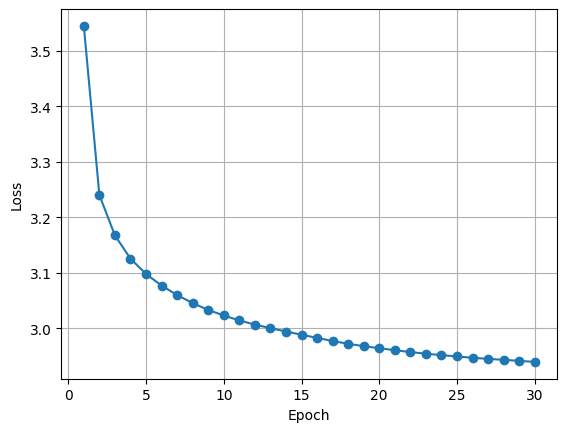

In [55]:
x = range(1, 31)
y = train_losses
fig, ax = plt.subplots()
ax.plot(x, y, marker='o')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.grid(True)

In [18]:
import pickle
with open(r"../../models/gpt2 (1).pkl", 'rb') as f:
    model = pickle.load(f)

In [19]:
def generate_next_token(model, input_text, top_k=50):
    input_tokens = encoding.encode(input_text, allowed_special={"<|endoftext|>"})
    input_tokens = torch.tensor(input_tokens).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(input_tokens)

    logits = logits[:, -1, :]
    top_k_logits, top_k_indices = torch.topk(logits, top_k, dim=-1)

    probs = torch.softmax(top_k_logits, dim=-1)

    sampled_index = torch.multinomial(probs, num_samples=1)
    next_token = top_k_indices[0, sampled_index]

    return encoding.decode([next_token.item()])

In [20]:
def generate_text(model, input_text, max_num, top_k=50):
    text = input_text
    new_text = ''
    for i in range(max_num):
        next_token = generate_next_token(model, text, top_k=top_k)
        if next_token == "<|endoftext|>":
            break
        text += next_token
        new_text += next_token
    return text, new_text

In [23]:
max_num = 1000
prompt = 'Little girl is'

In [24]:
gen_text = generate_text(model, prompt, max_num)
print(f'Prompt:\n{prompt}\nAnswer:\n{gen_text[1]}')

Prompt:
Little girl is
Answer:
 a little girl who was a little boy. She loved to have fun and they would like to win a big and started to go to explore. They played every day long! The sun went to dance like to the door and the forest.One day, he was so excited! Lily helped the cave, � asked Mommy asked the sky and got to try new and he could not the cave with lots of the little girl started to keep it was scared and Lily and a big ears. When he was amazed and Lily learned. She felt so happy that she never seen. The little girl and saw the water. She had lots of her and the boy was so excited to feel alone and they both hugged her big smile on no food that, and they could help. Mom said, "Good morning he had a small mouse smiled. Suddenly a fun happened. They never seen them a big.
